# Gear cutting with a rack cutter

Gears are not drawn but cut. A rack-shaped cutter rolls over the blank and, at every position, takes away what it
covers, and the involute flank is what is left. The example is two gears of module 2, one of 24 teeth and one of 10,
with the rolling done with Boolean operations, one subtraction per position. Below 17 teeth, the cutter's tip also
takes material from the tooth's foot, and the undercut appears by itself.

![A rack cutter rolling over a gear blank and cutting its teeth](../_static/gallery/gear-cutting.gif){.result}

In [1]:
import math
import time
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import planex as px

In [2]:
from docs_figures import Row

## The cutter

The basic rack has a module of `m` = 2 and flanks at `alpha` = 20°, a pitch of π m, and teeth half a pitch wide on
the pitch line. It cuts 1.25 m deep, so that the gear gets its root clearance (Figure 1).

In [3]:
m = 2.0
alpha = math.radians(20)
p = math.pi * m


def rack(teeth=3, depth=1.25 * m, back=3 * m):
    s = px.QuickSketch((-(teeth + 0.5) * p, back))
    top, tip = p / 4 + depth * math.tan(alpha), p / 4 - depth * math.tan(alpha)
    for n in range(-teeth, teeth + 1):
        s.Line((n * p - top, depth)).Line((n * p - tip, -depth)).Line((n * p + tip, -depth)).Line((n * p + top, depth))
    return s.Line(((teeth + 0.5) * p, depth)).Line(((teeth + 0.5) * p, back)).Close().Face()


cutter = rack()

In [4]:
Row((cutter, "Seven teeth of the basic rack"), caption="The rack cutter")

## Rolling

The blank turns by φ while the rack's pitch line rolls on the pitch circle r = m z / 2 without slipping, so the rack
moves by r φ. Shifting a rack by a whole pitch gives the same rack, so a short rack shifted by r φ modulo the pitch
cuts all the way around in one turn. The blank is a disc reaching one module beyond the pitch circle, and 1440 cuts
make a gear of 24 teeth (Figure 2).

In [5]:
def cuts(z, steps):
    r = m * z / 2
    angles = [2 * math.pi * n / steps for n in range(steps)]
    return [cutter.Translated(((r * phi) % p, r)).Rotated((0, 0), math.degrees(phi)) for phi in angles]


def cut(z, steps):
    return px.Subtract([px.QuickSketch().Circle(m * z / 2 + m).Face(), *cuts(z, steps)])


start = time.perf_counter()
gear24 = cut(24, 1440)
print("1440 cuts in", round(time.perf_counter() - start, 2), "s,", len(gear24.edges), "edges")

1440 cuts in 0.17 s, 12480 edges


In [6]:
Row((gear24, "24 teeth"), caption="The gear cut by 1440 positions of the rack")

## Check

**Checks:**

- on the pitch circle, a tooth is half a pitch wide, π m / 2, measured here as the gear's area in a thin ring;
- above the base circle, the cut flank is the involute, and the exact tooth of the [spur gear example](spur-gears.md)
  lies on top of it.

In [7]:
def inv(t):
    return math.tan(t) - t


def involute_gear(z):
    r = m * z / 2
    rb, ra, rf = r * math.cos(alpha), r + m, r - 1.25 * m
    beta = math.pi / (2 * z) + inv(alpha)
    ta = math.sqrt((ra / rb) ** 2 - 1)
    flank = []
    for n in range(21):
        t = ta * n / 20
        rt, phi = rb * math.sqrt(1 + t * t), -(beta - inv(math.atan(t)))
        flank.append((rt * math.cos(phi), rt * math.sin(phi)))
    other = [(x, -y) for x, y in flank]
    tip = 2 * math.degrees(beta - inv(math.atan(ta)))
    tooth = px.QuickSketch().Line(flank[0]).Spline(flank[1:]).Arc(center=(0, 0), sweep=tip)
    tooth = tooth.Spline(other[::-1][1:]).Close().Face()
    teeth = px.Unify([tooth.Rotated((0, 0), 360 * n / z) for n in range(z)] + [px.QuickSketch().Circle(rf).Face()])
    return teeth.Rotated((0, 0), 90 - 180 / z)


def tooth(gear, z, radius, band=0.01):
    ring = px.QuickSketch().Circle(radius + band / 2).Circle(radius - band / 2).Face()
    return (gear * ring).mass / band / z


r = m * 24 / 2
rb = r * math.cos(alpha)
exact24 = involute_gear(24)
print("tooth on the pitch circle", round(tooth(gear24, 24, r), 7), "π m / 2", round(math.pi * m / 2, 7))
print("tooth just above the base circle: cut", round(tooth(gear24, 24, rb + 0.1), 5), "involute",
      round(tooth(exact24, 24, rb + 0.1), 5))

tooth on the pitch circle 3.1415927 π m / 2 3.1415927
tooth just above the base circle: cut 3.62788 involute 3.6279


## Undercut

The involute starts on the base circle. With fewer than 2 / sin²α ≈ 17 teeth, the cutter's tip reaches below the
point where the flank meets the base circle and takes material from the tooth's foot, which weakens it. The 10-tooth
gear shows this: just above the base circle, its tooth is thinner than the involute one.

In [8]:
gear10 = cut(10, 1440)
exact10 = involute_gear(10)
rb10 = m * 10 / 2 * math.cos(alpha)
print("limit", round(2 / math.sin(alpha) ** 2, 1), "teeth")
print("10 teeth, just above the base circle: cut", round(tooth(gear10, 10, rb10 + 0.1), 5), "involute",
      round(tooth(exact10, 10, rb10 + 0.1), 5))

limit 17.1 teeth
10 teeth, just above the base circle: cut 3.23468 involute 3.24708


A tooth of each gear, with the involute tooth in red:

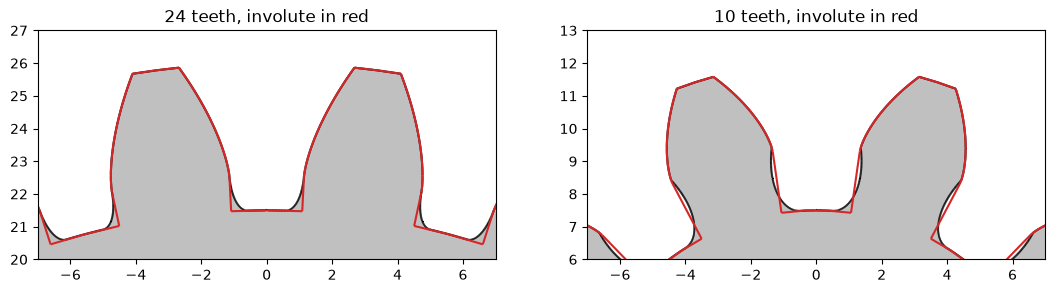

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, gear, exact, z in zip(axes, (gear24, gear10), (exact24, exact10), (24, 10)):
    gear.Plot(ax=ax, face_col="silver", legend=False)
    exact.Plot(ax=ax, face_col=None, line_col="tab:red", arc_col="tab:red", spline_col="tab:red", legend=False)
    ax.set_xlim(-7, 7)
    ax.set_ylim(m * z / 2 - 4, m * z / 2 + 3)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{z} teeth, involute in red")
plt.show()

## In motion

The animation shows the blank turning under the rack, cut by cut.

In [10]:
positions = cuts(24, 1440)
blank = px.QuickSketch().Circle(r + m).Face()
fig, ax = plt.subplots(figsize=(6, 6))


def frame(n):
    ax.clear()
    done = 24 * (n + 1)
    cut_so_far = px.Subtract([blank, *positions[:done]]).Rotated((0, 0), -360 * done / 1440)
    cut_so_far.Plot(ax=ax, face_col="silver", legend=False)
    cutter.Translated(((r * 2 * math.pi * done / 1440) % p, r)).Plot(ax=ax, face_col="tab:orange", legend=False)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-r - 4, r + 4)
    ax.set_ylim(-r - 4, r + 8)
    ax.axis("off")


animation = FuncAnimation(fig, frame, frames=60, interval=80)
plt.close(fig)
HTML(animation.to_jshtml())

In [11]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_animation(animation, "gear-cutting")